In [1]:
import numpy as np
import sys
sys.path.append("..") # So we can read modules
import modules.loaddata
import modules.nuwro
import torch
from torch import nn
from dataclasses import dataclass
import pandas as pd
import os
import re
import matplotlib.pyplot as plt

In [2]:
import importlib
importlib.reload(modules.loaddata)

<module 'modules.loaddata' from 'd:\\_\\plugg\\aman26\\pythonstuff\\nrf_gen\\..\\modules\\loaddata.py'>

In [3]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
if device == "cuda":
    print("CUDA available")
else:
    print("⚠️ CUDA not available ⚠️")

CUDA available


# Load data

In [5]:
def load_dat(path: str, skiplines = 3):
    data = np.loadtxt(path)
    with open(path, "r") as f:
        lines = f.readlines()
        headerline = lines[skiplines][1:]
        header = headerline.split()
    df = pd.DataFrame(data, columns=header)
    return df

In [23]:
# CURVETYPE_AVG = 0
# CURVETYPE_MIN = 1
# CURVETYPE_MAX = 2

class DataManager():
    def __init__(self, source_path: str = "./source_nrfs/"):

        # Find data files
        filenames = os.listdir(source_path)
        q_vals = []
        response_names = []
        names = []
        for filename in filenames:
            match = re.match(r"^([A-z]+)_([A-z0-9]+)_q(\d+)\.dat$", filename)
            if match:
                name = match.group(1)
                response_name = match.group(2)
                q_val = int(match.group(3))
                if not name in names:
                    names.append(name)
                if not response_name in response_names:
                    response_names.append(response_name)
                if not q_val in q_vals:
                    q_vals.append(q_val)

        if len(names) != 1:
            raise ValueError(f"Multiple names found in source path: {names}")
        

        # Load data from files
        omega_vals_flat = []
        q_vals_flat = []
        responses_flat = []

        for q in q_vals:
            omega_vals_for_q = None
            responses_for_q = []
            for response_name in response_names:
                filename = f"{names[0]}_{response_name}_q{q}.dat"
                df = load_dat(os.path.join(source_path, filename))
                if omega_vals_for_q is None:
                    omega_vals_for_q = df["omega"].values
                else:
                    if not np.isclose(df["omega"].values, omega_vals_for_q).all():
                        raise ValueError(f"Omega values do not match for {filename}")
                response = np.array([df["R"].values, df["R_low"].values, df["R_high"].values]).T
                responses_for_q.append(response)
            responses_flat.append(np.concatenate(responses_for_q, axis=1))
            omega_vals_flat.append(omega_vals_for_q)
            q_vals_flat.append(np.full_like(omega_vals_for_q, q))

        q_vals_flat = np.array(q_vals_flat).reshape(-1)
        omega_vals_flat = np.array(omega_vals_flat).reshape(-1)
        self.nrfs_flat = np.array(responses_flat).reshape(-1, len(response_names)*3)

        print("q Shape:", q_vals_flat.shape)
        print("omega Shape:", omega_vals_flat.shape)

        df = pd.DataFrame({
            "q": q_vals_flat,
            "omega": omega_vals_flat
        })

        
        self.df = df
        self.response_names = response_names

        self.nrf_count = len(response_names)

    def configure_data(self, q_to_test=[]):
        X_train = []
        Y_train = []
        
        X_test = []
        Y_test = []

        # train_mask = self.df["q"] != q_to_test
        test_mask = self.df["q"].isin(q_to_test)
        train_mask = ~test_mask

        X_train = self.df[train_mask][["omega", "q"]].values
        Y_train = self.nrfs_flat[train_mask]

        X_test = self.df[test_mask][["omega", "q"]].values
        Y_test = self.nrfs_flat[test_mask]

        X_train = np.array(X_train)
        Y_train = np.array(Y_train)
        X_test = np.array(X_test)
        Y_test = np.array(Y_test)

        print("TrainX Shape:", X_train.shape)
        print("TrainY Shape:", Y_train.shape)
        print("TestX Shape: ", X_test.shape)
        print("TestY Shape: ", Y_test.shape)

        X_train = torch.tensor(X_train, dtype=torch.float32).to(device)
        Y_train = torch.tensor(Y_train, dtype=torch.float32).to(device)
        
        X_test = torch.tensor(X_test, dtype=torch.float32).to(device)
        Y_test = torch.tensor(Y_test, dtype=torch.float32).to(device)

        # Normalized data
        self.X_mean = X_train.mean(dim=0, keepdim=True)
        self.X_std = X_train.std(dim=0, keepdim=True)
        self.Y_mean = Y_train.mean(dim=0, keepdim=True)
        self.Y_std = Y_train.std(dim=0, keepdim=True)

        X_train = self.x_to_normalised(X_train)
        Y_train = self.y_to_normalised(Y_train)
        
        X_test = self.x_to_normalised(X_test)
        Y_test = self.y_to_normalised(Y_test)


        self.X_train_GPU = X_train.to(device)
        self.Y_train_GPU = Y_train.to(device)
        self.X_test_GPU = X_test.to(device)
        self.Y_test_GPU = Y_test.to(device)
    
    def x_to_normalised(self, X):
        X = (X - self.X_mean) / self.X_std 
        return X
    def y_to_normalised(self, Y):
        Y = (Y - self.Y_mean) / self.Y_std
        return Y

    def x_from_normalized(self, X):
        X = X * self.X_std + self.X_mean
        return X
    def y_from_normalized(self, Y):
        Y = Y * self.Y_std + self.Y_mean
        return Y
    

In [25]:
# Load and configure data

# dm = DataManager("../data/O16_responses/O16_inversions/EM")
dm = DataManager("../data/O16_responses/O16_inversions/CR")
dm.configure_data([])

print("Response functions:", dm.response_names)

q Shape: (36009,)
omega Shape: (36009,)
TrainX Shape: (36009, 2)
TrainY Shape: (36009, 15)
TestX Shape:  (0, 2)
TestY Shape:  (0, 15)
Response functions: ['R00', 'R0z', 'Rxx', 'Rxy', 'Rzz']


# Neural network

In [ ]:
def mae_loss(y_pred: torch.Tensor, y_true: torch.Tensor) -> torch.Tensor:
    return torch.mean(torch.abs(y_pred - y_true))

@dataclass
class Params:
    layers: list[int]
    activation: nn.Module
    loss_fn: callable
    base_lr: float
    weight_decay: float


In [ ]:
params = Params(
    layers=[128,256,128,128,256,256,512],
    activation=nn.GELU(),
    loss_fn=mae_loss,
    base_lr=1e-3,
    weight_decay=1e-4,
)

In [12]:
class AbInitioNN(nn.Module):
    def __init__(self, nnParams, dataManager: DataManager):
        super().__init__()
        self.dataManager = dataManager
        self.nnParams = nnParams

        self.flatten = nn.Flatten()
        
        self.layer_stack = nn.Sequential()
        self.layer_stack.add_module("input_layer", nn.Linear(2, nnParams.layers[0]))
        self.layer_stack.add_module(f"activation_0", nnParams.activation)
        for i, layer_size in enumerate(nnParams.layers[1:], start=1):
            self.layer_stack.add_module(f"layer_{i}", nn.Linear(nnParams.layers[i-1], layer_size))
            self.layer_stack.add_module(f"activation_{i}", nnParams.activation)
        self.layer_stack.add_module("output_layer", nn.Linear(nnParams.layers[-1], dataManager.nrf_count*3))
        
        self.to(device)
        

        self.loss_fn = nnParams.loss_fn
        self.optimizer = torch.optim.AdamW(self.parameters(), lr=nnParams.base_lr, weight_decay=nnParams.weight_decay)

        self.train_loss_history = []
        self.test_loss_history = []


    def forward(self, x):
        x = self.flatten(x)
        logits = self.layer_stack(x)
        return logits
    
    def train_single_iteration(self, X, y, log: bool): # Only run this when the setup in train_for has been done
        pred = self(X)
        loss = self.loss_fn(pred, y)
        loss.backward()
        self.optimizer.step()
        self.optimizer.zero_grad()

        loss = loss.item()
        self.train_loss_history.append(loss)
        if log:
            print(f"loss: {loss:>7f} ")
    
    def train_for(self, steps: int, log: bool = True):
        '''
        Train the network on the data provided by the DataManager for the given number of steps.
        - steps: Number of epochs to run for
        - log: Whether to print info during training. Disable to clear up the output
        '''
        self.train()
        # X, y = next(iter(self.dataManager.train_dataloader)) # Everything fits in one batch, saves on data transfer to GPU
        # X, y = X.to(device), y.to(device)
        for t in range(steps):
            if log:
                print(f"Epoch {t+1}\n-------------------------------")
            self.train_single_iteration(self.dataManager.X_train_GPU, self.dataManager.Y_train_GPU, log)
            self.test(log=log)
        if log:
            print("Done!")
    
    def test(self, log: bool = True):
        if len(self.dataManager.X_test_GPU) == 0:
            return 0
        self.eval()
        # X, y = next(iter(self.dataManager.test_dataloader))
        # X, y = X.to(device), y.to(device)
        loss = 0
        with torch.no_grad():
            pred = self(self.dataManager.X_test_GPU)
            loss = self.loss_fn(pred, self.dataManager.Y_test_GPU).item()
            self.test_loss_history.append(loss)
        if log:
            print(f"Test loss: {loss:>8f} \n")
        return loss
    
    def make_transformed_prediction(self, qvals, wvals):
        
        inputs = torch.tensor([[w, q] for w, q in zip(wvals, qvals)], dtype=torch.float32).to(device)
        inputs =self.dataManager.x_to_normalised(inputs)
        with torch.no_grad():
            preds = self(inputs)
            preds = self.dataManager.y_from_normalized(preds).cpu().numpy()
        return preds

In [13]:
net = AbInitioNN(params, dm)
net.train_for(steps=5000, log=True)

Epoch 1
-------------------------------
loss: 0.608099 
Epoch 2
-------------------------------
loss: 0.598114 
Epoch 3
-------------------------------
loss: 0.587937 
Epoch 4
-------------------------------
loss: 0.576686 
Epoch 5
-------------------------------
loss: 0.563373 
Epoch 6
-------------------------------
loss: 0.546723 
Epoch 7
-------------------------------
loss: 0.525036 
Epoch 8
-------------------------------
loss: 0.496169 
Epoch 9
-------------------------------
loss: 0.462771 
Epoch 10
-------------------------------
loss: 0.451558 
Epoch 11
-------------------------------
loss: 0.463300 
Epoch 12
-------------------------------
loss: 0.422349 
Epoch 13
-------------------------------
loss: 0.409565 
Epoch 14
-------------------------------
loss: 0.414713 
Epoch 15
-------------------------------
loss: 0.408008 
Epoch 16
-------------------------------
loss: 0.390349 
Epoch 17
-------------------------------
loss: 0.371476 
Epoch 18
-------------------------------

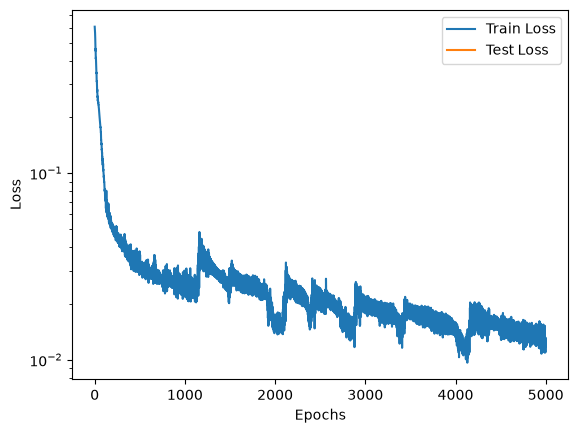

In [14]:
plt.plot(net.train_loss_history, label="Train Loss")
plt.plot(net.test_loss_history, label="Test Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.yscale("log")
plt.legend()

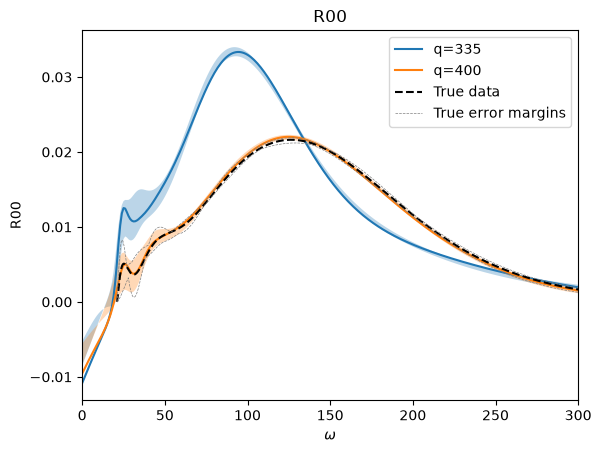

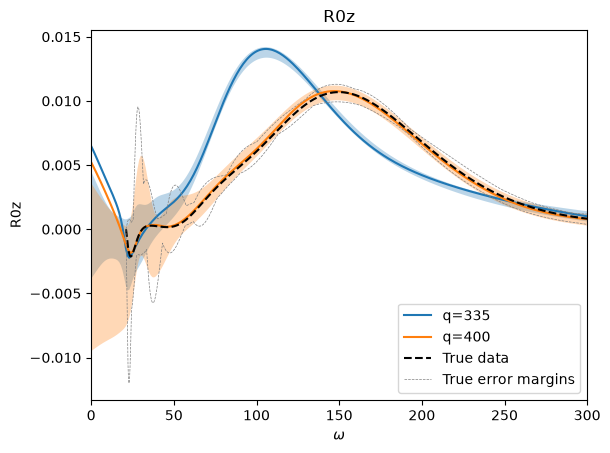

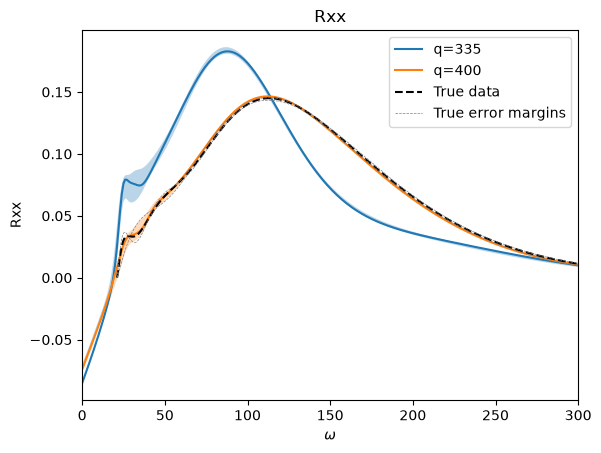

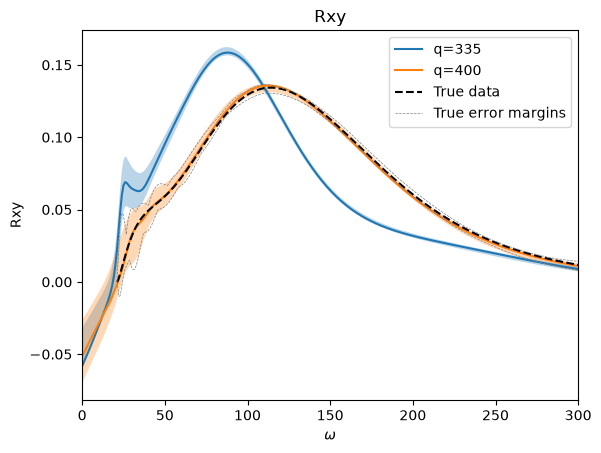

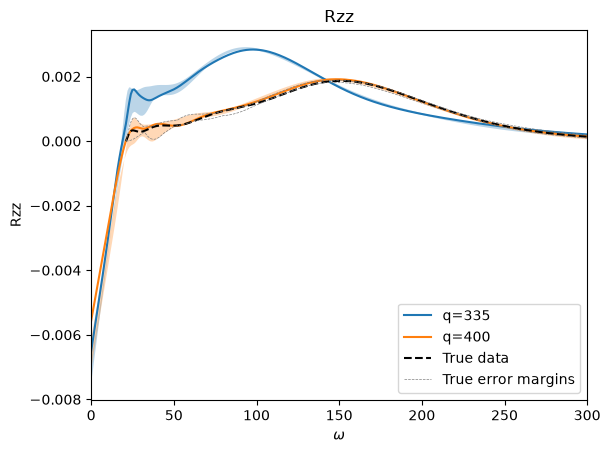

In [33]:
for i, name in enumerate(dm.response_names):
    first = True
    plt.figure()
    for q in [335, 400]:
        label = None
        preds = net.make_transformed_prediction([q] * 500, np.arange(0, 500, 1))
        plt.plot(np.arange(0, 500, 1), preds[:, i*3], label=f"q={q}")
        plt.fill_between(np.arange(0, 500, 1), preds[:, i*3 + 1], preds[:, i*3 + 2], alpha=0.3)
        if dm.df[dm.df["q"] == q].shape[0] > 0:
            label = None
            label2 = None
            if first:
                label = f"True error margins"
                label2 = "True data"
                first = False
            plt.plot(dm.df[dm.df["q"] == q]["omega"], dm.nrfs_flat[dm.df["q"] == q, i*3], color="black", linestyle="dashed", label = label2)
            plt.plot(dm.df[dm.df["q"] == q]["omega"], dm.nrfs_flat[dm.df["q"] == q, i*3 + 1], color="gray", linestyle="dashed", linewidth=0.5, label=label)
            plt.plot(dm.df[dm.df["q"] == q]["omega"], dm.nrfs_flat[dm.df["q"] == q, i*3 + 2], color="gray", linestyle="dashed", linewidth=0.5)
    plt.legend()
    plt.xlabel("$\\omega$")
    plt.ylabel(dm.response_names[i])
    plt.title(dm.response_names[i])
    plt.xlim(0, 300)

# Export NRFs

In [28]:
grid_spacing = 4.0
grid_steps = 300

grid = np.arange(0, grid_steps * grid_spacing, grid_spacing)
w, q = np.meshgrid(grid, grid)

pred = net.make_transformed_prediction(q.flatten(), w.flatten())

# plt.imshow(pred[:, 0].reshape(grid_steps, grid_steps), extent=(0, grid_steps * grid_spacing, 0, grid_steps * grid_spacing), origin='lower', aspect='auto')

res = ""

to_invert = ["Rxy"]

# lowest_w_in_data = dm.df["omega"].min()
# print("Lowest w in data:", lowest_w_in_data)
# is_above_lowest_w = w.flatten() > lowest_w_in_data
is_above_lowest_w = 1

for i, nrf in enumerate(dm.response_names):
    sign = -1.0 if nrf in to_invert else 1.0
    val = pred[:, i*3]* is_above_lowest_w
    val = np.maximum(val, 0) # Clamp values positive
    val *= sign
    res += modules.nuwro.ListToCppArray(val, f'nrf_{nrf}')

res += "static double *neutrino_nrfs[] = {"

# for nrf in dm.response_names:
for nrf in ["R00", "R0z", "Rzz", "Rxx", "Rxy"]: # Ensure correct NRF order
    res += f"nrf_{nrf}, "
res = res[:-2]
res += "};"

with open("nrf_export.cpp", "w") as f:
    f.write(res)

# Slask/löst bös

In [279]:
example_xsec = np.loadtxt("../data/exp_oxygen_537_37.csv")
more_data = np.loadtxt("../aa.txt")

C:\Users\griff\AppData\Local\Temp\ipykernel_24908\1134231519.py:3: RuntimeWarning: invalid value encountered in arccos
  return np.arccos((q**2 - eps**2 - (eps-w)**2) / (-2 * eps * (eps-w)))
C:\Users\griff\AppData\Local\Temp\ipykernel_24908\1134231519.py:28: RuntimeWarning: divide by zero encountered in divide
  xsec_mott = fine_structure**2 * np.cos(theta/2)**2 / (4 * eps**2 * np.sin(theta/2)**4)
C:\Users\griff\AppData\Local\Temp\ipykernel_24908\1134231519.py:39: RuntimeWarning: invalid value encountered in multiply
  xsec *= xsec_mott
C:\Users\griff\AppData\Local\Temp\ipykernel_24908\1134231519.py:40: RuntimeWarning: invalid value encountered in multiply
  xsec_low *= xsec_mott
C:\Users\griff\AppData\Local\Temp\ipykernel_24908\1134231519.py:41: RuntimeWarning: invalid value encountered in multiply
  xsec_high *= xsec_mott


Text(0.5, 0.98, 'q=330 MeV, $\\epsilon$=537 MeV')

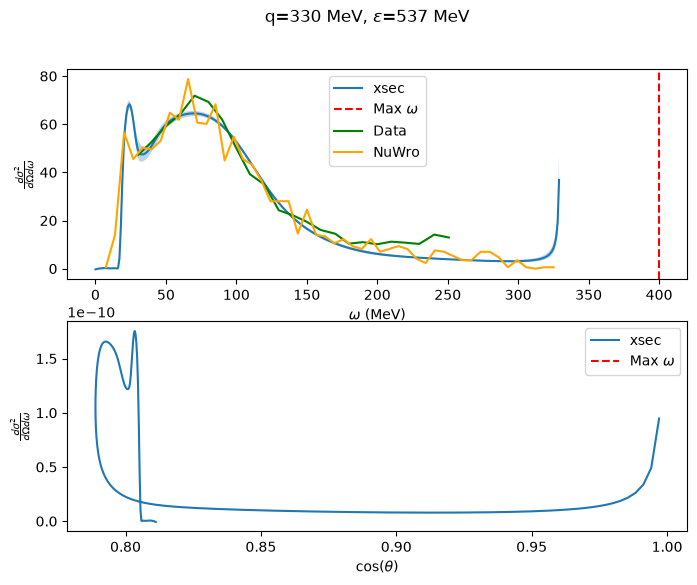

In [312]:
unit_convert =3.8938e4 * 1e7
def wq_to_theta(q, eps, w):
    return np.arccos((q**2 - eps**2 - (eps-w)**2) / (-2 * eps * (eps-w)))
def wtheta_to_q(eps, w, theta):
    return np.sqrt(eps**2 + (eps-w)**2 - 2 * eps * (eps-w) * np.cos(theta))

q = 330
# theta = 37.1 * np.pi / 180
# costheta = np.cos(theta)
# maxw = np.minimum(q, 2 * eps - q)
maxw = 400

w = np.arange(0, maxw, 1)
# q = wtheta_to_q(w, 0, costheta)
eps = 537

eps_prim = eps - w

Q_sq = q**2 - w**2
theta = wq_to_theta(q, eps, w)

# q^2 - eps^2 - (eps-w)^2 = q^2 - 2eps^2 + 2eps w - w^2 = 1
# w^2 - w 2 eps + 2 eps^2 - q^2 - 1 = 0
# -> w = -eps +/- sqrt(eps^2 - 2 eps^2 + q^2 + 1) = -eps +/- sqrt(q^2 - eps^2 + 1)

fine_structure= 1/137.036

xsec_mott = fine_structure**2 * np.cos(theta/2)**2 / (4 * eps**2 * np.sin(theta/2)**4)
vRL = (Q_sq/q**2)**2
vRT = (Q_sq/(2*q**2) + np.tan(theta/2)**2)

nrfs = net.make_transformed_prediction([q]*len(w), w)

xsec = vRL * nrfs[:, 0] + vRT * nrfs[:, 3]
xsec_low = vRL * nrfs[:, 1] + vRT * nrfs[:, 4]
xsec_high = vRL * nrfs[:, 2] + vRT * nrfs[:, 5]

# xsec = 1
xsec *= xsec_mott
xsec_low *= xsec_mott
xsec_high *= xsec_mott

fig, axs = plt.subplots(2, 1, figsize=(8, 6))

ax1 = axs[0]
ax2 = axs[1]

ax1.plot(w, xsec * unit_convert, label="xsec")
ax1.fill_between(w, xsec_low * unit_convert, xsec_high * unit_convert, alpha=0.3)
ax1.axvline(maxw, color="red", linestyle="--", label="Max $\\omega$")
# plt.xlim(0, q + 100)
# plt.plot(w,theta * 1e53)
ax1.set_xlabel("$\\omega$ (MeV)")
ax1.set_ylabel("$\\frac{d\\sigma^2}{d\\Omega d \\omega}$")

ax1.plot(example_xsec[:, 0], example_xsec[:, 1], color="green", label="Data")
ax1.plot(more_data[:, 0], more_data[:, 1] * 1e36 * 2  * np.pi/8, color="orange", label="NuWro")
ax1.legend()

# ax1.set_ylim(-1e14, 1e-13)

ax2.plot(np.cos(theta), xsec, label="xsec")
ax2.axvline(np.cos(wq_to_theta(q, eps, maxw)), color="red", linestyle="--", label="Max $\\omega$")
ax2.set_xlabel("$\\cos(\\theta)$")
ax2.set_ylabel("$\\frac{d\\sigma^2}{d\\Omega d \\omega}$")
ax2.legend()
# ax2.set_ylim(-1e-13)

plt.suptitle(f"q={q} MeV, $\\epsilon$={eps} MeV")

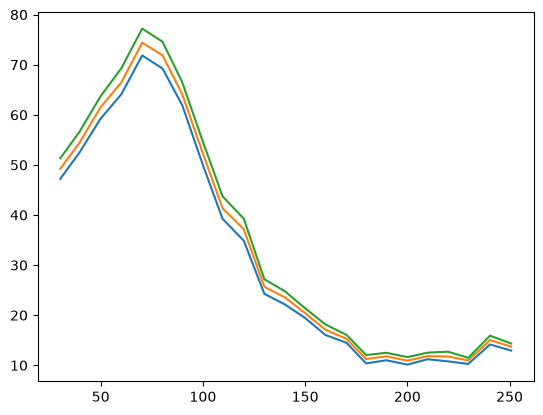

In [212]:
for i in range(1, 4):
    plt.plot(a[:, 0], a[:, i], label=f"NRF {i}")


C:\Users\griff\AppData\Local\Temp\ipykernel_24908\3305563636.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


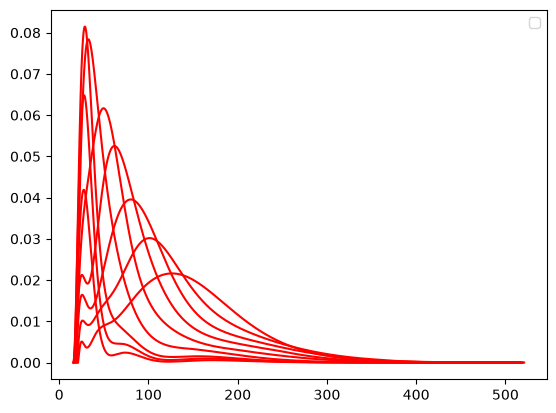

In [ ]:
mask = dm.df["q"] != 30000
for i, name in enumerate(dm.response_names):
    if i != 0:
        continue
    for q in np.unique(dm.df[mask]["q"]):
        mask2 = (dm.df["q"] == q)
        plt.plot(dm.df[mask2]["omega"], dm.nrfs_flat[mask2, i*3], color=["red", "blue", "green", "orange", "purple"][i])
plt.legend()
# plt.plot(dm.df[mask]["omega"], dm.df[mask]["Rxx"], label="R00")

(0.0, 250.0)

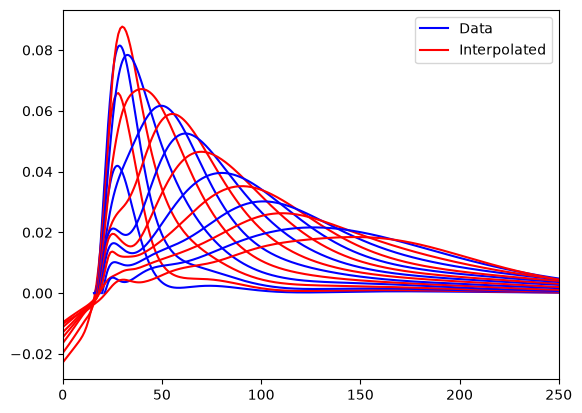

In [ ]:
a = False
b = False
for q in np.arange(50, 450, 25):
    label = None
    col = "red"
    if q % 50 != 25:
        col = "blue"
        if not a:
            label = "Data"
            a = True
        plt.plot(dm.df[dm.df["q"] == q]["omega"], dm.nrfs_flat[dm.df["q"] == q, 0], label=label, color=col)
    else:
        if not b:
            label = "Interpolated"
            b = True
        preds = net.make_transformed_prediction([q] * 500, np.arange(0, 500, 1))
        plt.plot(np.arange(0, 500, 1), preds[:, 0], label=label, color=col)
plt.legend()
plt.xlim(0, 250)

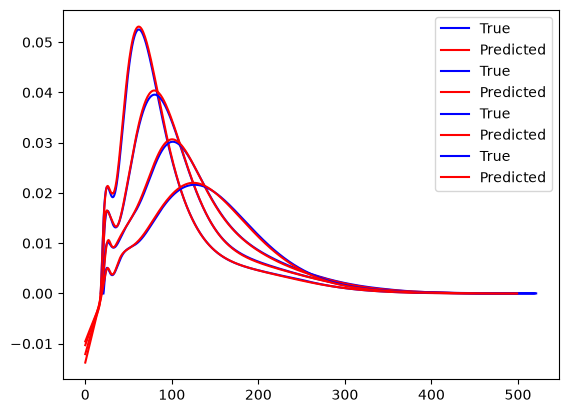

In [ ]:
nrf_i = 0
for left_out_q in [250, 300, 350, 400]:
    pred = net.make_transformed_prediction([left_out_q] * 500, np.arange(0, 500, 1))
    true_mask = dm.df["q"] == left_out_q

    plt.plot(dm.df[true_mask]["omega"], dm.nrfs_flat[true_mask, 3*nrf_i], label="True", color="blue")
    plt.plot(np.arange(0, 500, 1), pred[:, 3*nrf_i], label="Predicted", color="red")

plt.legend()